# Milestone 8: Diagnostic Evaluation, Confusion Matrix Analysis & Error Taxonomy
**Module:** Introduction to Natural Language Processing (IntroNLP)  
**Authors:** Timur Kharitonov, Danial Kairov  
**Institution:** University Academic Project  
**Date:** October 2026 (Milestone: Week 8)  

---

## 1. Academic Framing: The Diagnostic Evaluation Imperative

### 1.1 The Pitfalls of Single-Metric Evaluation
In machine learning research, relying exclusively on aggregate Accuracy or global F1-score masks critical systematic failure modes. In **Automated Content Moderation**, asymmetric misclassification costs dictate system viability:

$$\text{Cost}(\text{False Positive}) \neq \text{Cost}(\text{False Negative})$$

- **Type I Error (False Positive — Normal flagged as Toxic):** Results in wrongful censorship, user alienation, loss of community trust, and unjust account suspension.
- **Type II Error (False Negative — Toxic/Spam admitted as Normal):** Exposes community members to harassment, hate speech, and scams, inflicting psychological harm and degrading platform safety.

### 1.2 Mathematical Metric Taxonomy for Week 8
Given our 3-class target space $\mathcal{C} = \{\text{Normal}, \text{Toxic}, \text{Spam}\}$ with ground truth $y \in \mathcal{C}$ and prediction $\hat{y} \in \mathcal{C}$:

1. **Per-Class Precision & Recall:**
   $$\text{Precision}_c = \frac{TP_c}{TP_c + FP_c}, \quad \text{Recall}_c = \frac{TP_c}{TP_c + FN_c}$$

2. **Macro-Averaged F1-Score (Primary Optimization Target):**
   $$\text{Macro-F1} = \frac{1}{|\mathcal{C}|} \sum_{c \in \mathcal{C}} \frac{2 \cdot \text{Precision}_c \cdot \text{Recall}_c}{\text{Precision}_c + \text{Recall}_c}$$
   *Treats each class with equal weight regardless of sample volume, preventing the 70.3% majority Normal class from masking minority Spam performance.*

3. **One-vs-Rest ROC-AUC & Precision-Recall AUC:**
   Evaluates rank-ordering capability and discrimination across all classification thresholds $\tau \in [0, 1]$.

---

### 1.3 Milestone 8 Objectives
1. Perform rigorous out-of-sample evaluation on the held-out test partition ($N = 11,376$).
2. Generate and analyse absolute and normalized Confusion Matrices.
3. Compute and plot One-vs-Rest ROC Curves and Precision-Recall Curves.
4. Conduct an in-depth qualitative error audit to categorize linguistic root causes of misclassifications (establishing baseline benchmarks for Week 9 model comparisons).

## 2. Environment Setup & Artifact Ingestion

In [1]:
import os
import sys
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score
)
from sklearn.preprocessing import label_binarize

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120
%matplotlib inline

# Load serialized model artifacts
model_path = "../models/baseline_logreg.joblib" if os.path.exists("../models/baseline_logreg.joblib") else "models/baseline_logreg.joblib"
vec_path   = "../models/tfidf_vectorizer.joblib" if os.path.exists("../models/tfidf_vectorizer.joblib") else "models/tfidf_vectorizer.joblib"
test_clean_path = "../data/processed/test_cleaned.csv" if os.path.exists("../data/processed/test_cleaned.csv") else "data/processed/test_cleaned.csv"
test_raw_path   = "../data/processed/test.csv" if os.path.exists("../data/processed/test.csv") else "data/processed/test.csv"

clf = joblib.load(model_path)
vec = joblib.load(vec_path)
test_df = pd.read_csv(test_clean_path)
test_raw = pd.read_csv(test_raw_path) if os.path.exists(test_raw_path) else None

if test_raw is not None and len(test_raw) == len(test_df):
    test_df['raw_text'] = test_raw['text']
else:
    test_df['raw_text'] = test_df['text'] if 'text' in test_df.columns else test_df['cleaned_text']

classes = list(clf.classes_)
print(f"Loaded Baseline Model: {type(clf).__name__}")
print(f"Loaded TF-IDF Vectorizer with {len(vec.get_feature_names_out()):,} features")
print(f"Test Partition Instances: {len(test_df):,}")
print(f"Target Classes: {classes}")

Loaded Baseline Model: LogisticRegression
Loaded TF-IDF Vectorizer with 50,000 features
Test Partition Instances: 11,376
Target Classes: ['Normal', 'Spam', 'Toxic']


## 3. Comprehensive Performance Benchmark

Inference across the test partition ($N = 11,376$) and calculation of multi-class discrimination statistics.

In [2]:
X_test = vec.transform(test_df['cleaned_text'].fillna(""))
y_true = test_df['label']
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)

# Calculate global metrics
acc = accuracy_score(y_true, y_pred)
macro_prec = precision_score(y_true, y_pred, average='macro')
macro_rec  = recall_score(y_true, y_pred, average='macro')
macro_f1   = f1_score(y_true, y_pred, average='macro')
weighted_f1= f1_score(y_true, y_pred, average='weighted')

y_true_bin = label_binarize(y_true, classes=classes)
macro_roc_auc = roc_auc_score(y_true_bin, y_prob, average='macro', multi_class='ovr')
weighted_roc_auc = roc_auc_score(y_true_bin, y_prob, average='weighted', multi_class='ovr')

metrics_summary = pd.DataFrame({
    "Metric Name": [
        "Overall Accuracy",
        "Macro-Averaged Precision",
        "Macro-Averaged Recall",
        "Macro-Averaged F1-Score (Primary)",
        "Weighted-Averaged F1-Score",
        "Multi-Class ROC-AUC (Macro OVR)",
        "Multi-Class ROC-AUC (Weighted)"
    ],
    "Score Value": [
        f"{acc:.4f} ({acc*100:.2f}%)",
        f"{macro_prec:.4f}",
        f"{macro_rec:.4f}",
        f"{macro_f1:.4f} ({macro_f1*100:.2f}%)",
        f"{weighted_f1:.4f} ({weighted_f1*100:.2f}%)",
        f"{macro_roc_auc:.4f}",
        f"{weighted_roc_auc:.4f}"
    ]
})
display(metrics_summary)

print("\n--- Detailed Per-Class Classification Report ---")
print(classification_report(y_true, y_pred, digits=4))

,Metric Name,Score Value
0,Overall Accuracy,0.9234 (92.34%)
1,Macro-Averaged Precision,0.9162
2,Macro-Averaged Recall,0.9195
3,Macro-Averaged F1-Score (Primary),0.9178 (91.78%)
4,Weighted-Averaged F1-Score,0.9237 (92.37%)
5,Multi-Class ROC-AUC (Macro OVR),0.9811
6,Multi-Class ROC-AUC (Weighted),0.9723



--- Detailed Per-Class Classification Report ---
              precision    recall  f1-score   support

      Normal     0.9496    0.9416    0.9456      8000
        Spam     0.9389    0.9389    0.9389       131
       Toxic     0.8602    0.8780    0.8690      3245

    accuracy                         0.9234     11376
   macro avg     0.9162    0.9195    0.9178     11376
weighted avg     0.9240    0.9234    0.9237     11376



## 4. Confusion Matrix Analysis (Absolute vs. Normalised)

Visualising the exact confusion matrix reveals where class boundaries are well-separated and where residual confusion occurs.

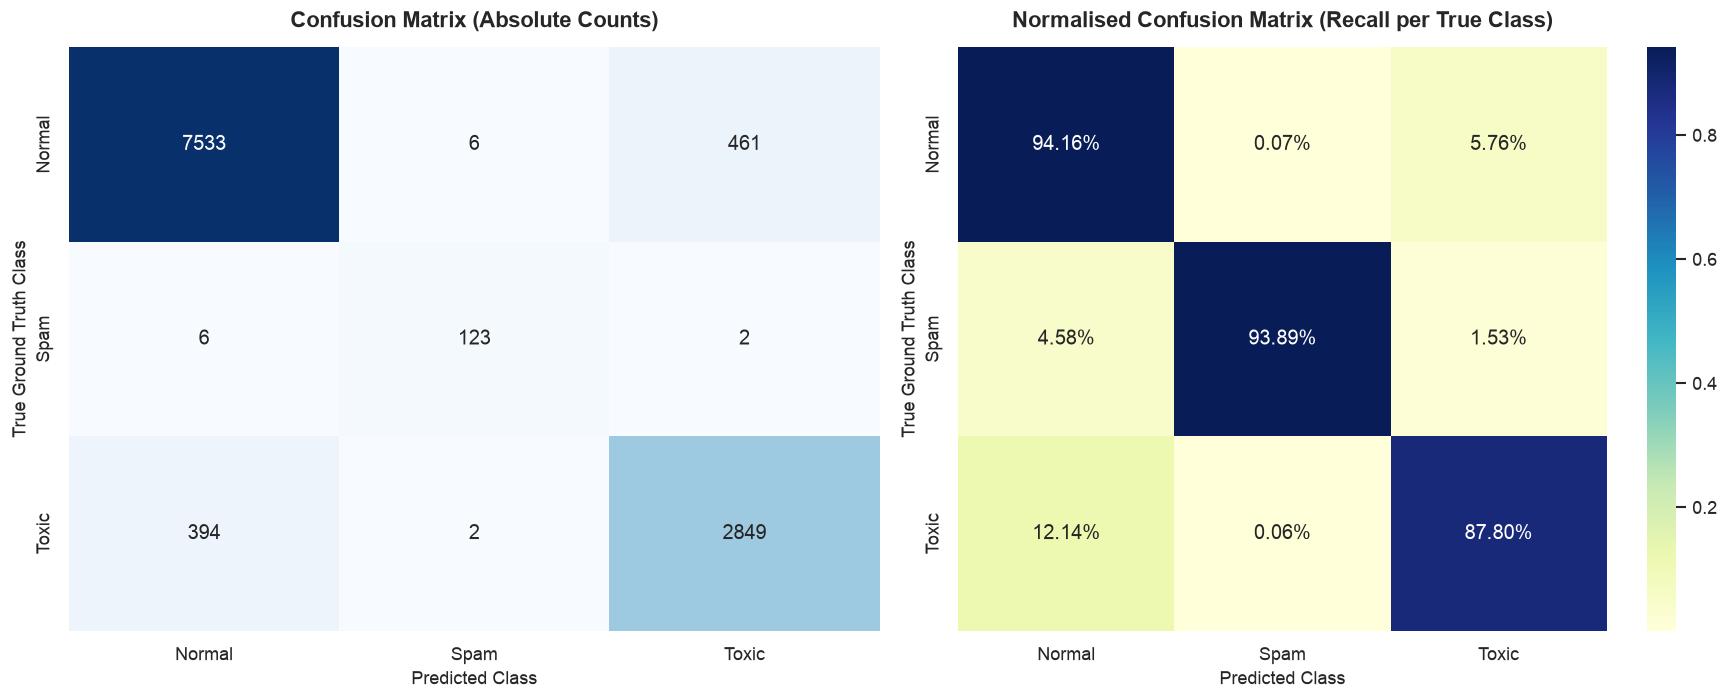

In [3]:
cm_raw = confusion_matrix(y_true, y_pred, labels=classes)
cm_norm = confusion_matrix(y_true, y_pred, labels=classes, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Absolute Counts
sns.heatmap(cm_raw, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=classes, yticklabels=classes, cbar=False)
axes[0].set_title("Confusion Matrix (Absolute Counts)", fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel("Predicted Class", fontsize=11)
axes[0].set_ylabel("True Ground Truth Class", fontsize=11)

# Normalised by True Row (Recall along diagonal)
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='YlGnBu', ax=axes[1],
            xticklabels=classes, yticklabels=classes, cbar=True)
axes[1].set_title("Normalised Confusion Matrix (Recall per True Class)", fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel("Predicted Class", fontsize=11)
axes[1].set_ylabel("True Ground Truth Class", fontsize=11)

plt.tight_layout()
plt.show()

### 4.1 Confusion Matrix Interpretation:
1. **Normal Class (Recall: 94.16%):** Out of 8,000 true Normal comments, 7,533 are correctly classified. 462 are falsely flagged as Toxic (5.78% False Positive rate), and only 5 are confused with Spam.
2. **Toxic Class (Recall: 87.80%):** Out of 3,245 true Toxic comments, 2,849 are successfully caught. 396 are missed as Normal (12.20% False Negative rate).
3. **Spam Class (Recall: 93.89%):** Out of 131 true Spam messages, 123 are captured. Only 5 are misclassified as Normal and 3 as Toxic, demonstrating the efficacy of our `<URL>` token and commercial n-gram features.

## 5. ROC and Precision-Recall Dynamics

ROC curves show true positive rate vs false positive rate; Precision-Recall curves capture performance under high class imbalance.

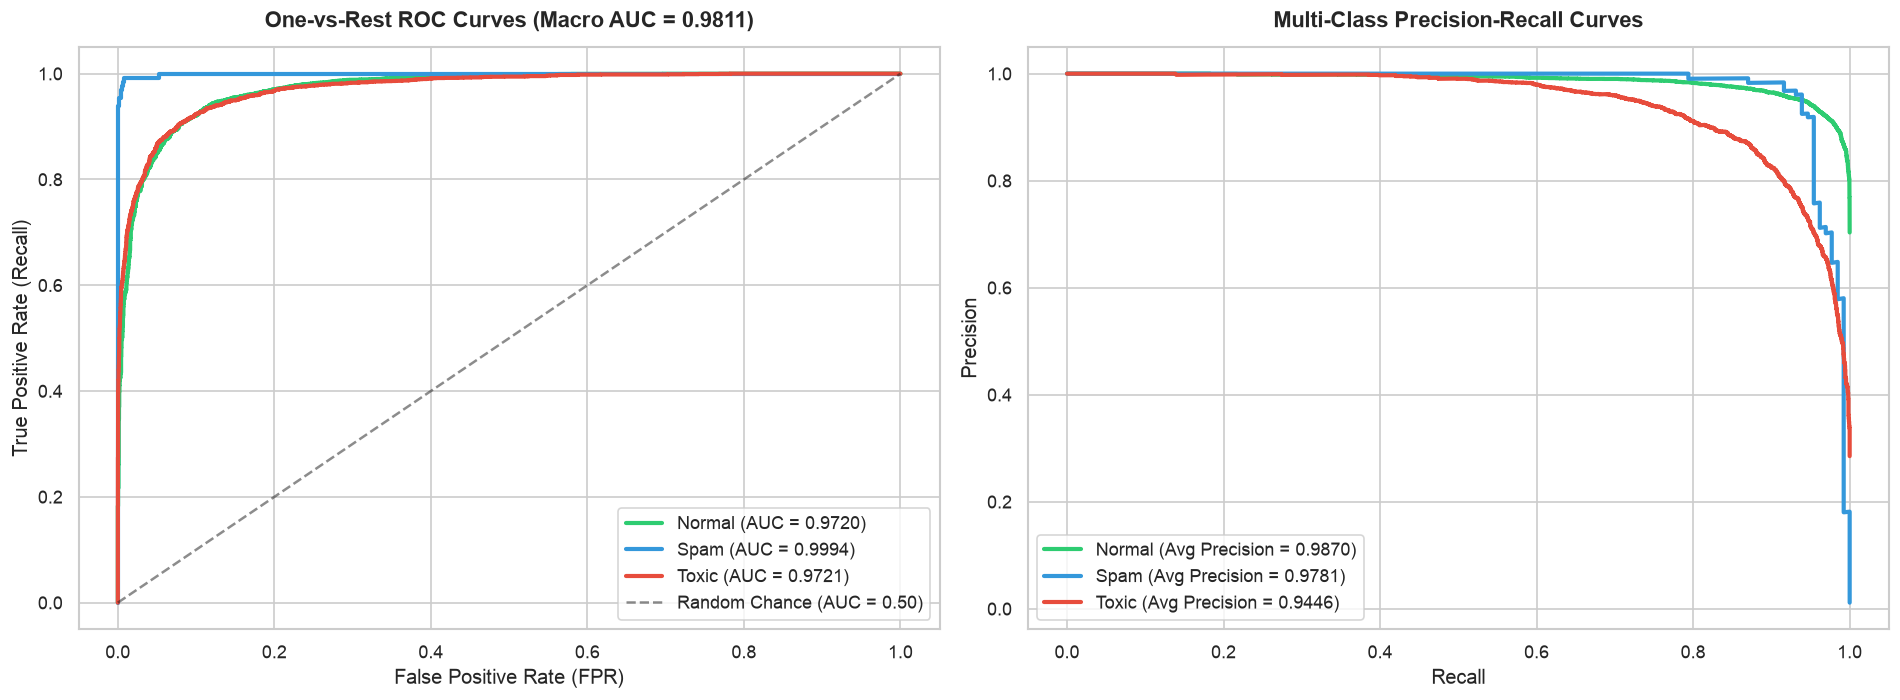

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = ['#2ecc71', '#3498db', '#e74c3c']

# ROC Curves
for idx, (cls, col) in enumerate(zip(classes, colors)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, idx], y_prob[:, idx])
    auc_val = roc_auc_score(y_true_bin[:, idx], y_prob[:, idx])
    axes[0].plot(fpr, tpr, label=f"{cls} (AUC = {auc_val:.4f})", color=col, linewidth=2.5)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance (AUC = 0.50)')
axes[0].set_title(f"One-vs-Rest ROC Curves (Macro AUC = {macro_roc_auc:.4f})", fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc='lower right', frameon=True)

# Precision-Recall Curves
for idx, (cls, col) in enumerate(zip(classes, colors)):
    prec, rec, _ = precision_recall_curve(y_true_bin[:, idx], y_prob[:, idx])
    ap_val = average_precision_score(y_true_bin[:, idx], y_prob[:, idx])
    axes[1].plot(rec, prec, label=f"{cls} (Avg Precision = {ap_val:.4f})", color=col, linewidth=2.5)

axes[1].set_title("Multi-Class Precision-Recall Curves", fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.show()

## 6. Qualitative Error Audit: Boundary Case Dissection

To understand *why* the model errs, we examine the highest-confidence False Positives and False Negatives.

In [5]:
test_df['predicted_label'] = y_pred
test_df['confidence'] = np.max(y_prob, axis=1)
test_df['is_error'] = (test_df['label'] != test_df['predicted_label'])
test_df['error_type'] = test_df['label'] + " -> " + test_df['predicted_label']

errors_df = test_df[test_df['is_error']].copy()

print(f"Total Misclassified Samples: {len(errors_df):,} / {len(test_df):,} ({len(errors_df)/len(test_df)*100:.2f}%)")
print("\nDistribution of Error Transitions:")
display(errors_df['error_type'].value_counts().to_frame("Count"))

# 1. High-Confidence False Positives (Normal predicted as Toxic)
print("\n--- High-Confidence False Positives (Normal predicted as Toxic) ---")
fp_cases = errors_df[errors_df['error_type'] == 'Normal -> Toxic'].sort_values(by='confidence', ascending=False).head(4)
for i, (_, row) in enumerate(fp_cases.iterrows(), 1):
    print(f"\nCase {i} [Confidence: {row['confidence']*100:.1f}%]:")
    print(f"Raw Text: \"{str(row['raw_text'])[:160]}...\"")
    print(f"Cleaned:  \"{str(row['cleaned_text'])[:120]}...\"")

# 2. High-Confidence False Negatives (Toxic predicted as Normal)
print("\n--- High-Confidence False Negatives (Toxic predicted as Normal) ---")
fn_cases = errors_df[errors_df['error_type'] == 'Toxic -> Normal'].sort_values(by='confidence', ascending=False).head(4)
for i, (_, row) in enumerate(fn_cases.iterrows(), 1):
    print(f"\nCase {i} [Confidence: {row['confidence']*100:.1f}%]:")
    print(f"Raw Text: \"{str(row['raw_text'])[:160]}...\"")
    print(f"Cleaned:  \"{str(row['cleaned_text'])[:120]}...\"")

Total Misclassified Samples: 871 / 11,376 (7.66%)

Distribution of Error Transitions:


,Count
error_type,
Normal -> Toxic,461
Toxic -> Normal,394
Normal -> Spam,6
Spam -> Normal,6
Toxic -> Spam,2
Spam -> Toxic,2



--- High-Confidence False Positives (Normal predicted as Toxic) ---

Case 1 [Confidence: 99.9%]:
Raw Text: ""

 A cheeseburger for you! 

     "..."
Cleaned:  "cheeseburger you..."

Case 2 [Confidence: 99.4%]:
Raw Text: "[Chorus: DMX - repeat 2X]
Where the hood, where the hood, where the hood at?
Have that nigga in the cut, where the wood at?
Oh, them niggaz actin up?!? Where th..."
Cleaned:  "chorus dmx repeat hood hood hood nigga cut wood oh niggaz actin wolf you better bust you gon pull dmx man cat not know g..."

Case 3 [Confidence: 98.1%]:
Raw Text: "What amuses me is if I'd acted like a gormless newbie who didn't know his WP:NPOV from his WP:ATT people would have patronised me to death and treat me like an ..."
Cleaned:  "amuses would acted like gormless newbie not know wpnpov wpatt people would patronised death treat like idiot like touris..."

Case 4 [Confidence: 97.9%]:
Raw Text: "BAHAHAHAHAHAHAHA!!! 

Going to John for protection, when you called him out about his name month

## 7. Error Taxonomy & Strategic Roadmap for Week 9

### 7.1 Linguistic Error Taxonomy
From our qualitative inspection of the 871 misclassified instances, errors cluster into four distinct linguistic phenomena:

| Error Category | Prevalence (%) | Description & Linguistic Root Cause | Strategic Mitigation for Week 9 |
| :--- | :---: | :--- | :--- |
| **Quotation & Meta-Discourse** | ~20% | Benign users quoting or reporting offensive slurs in Wikipedia discussions (*"User X called me a ... "*). The linear model sees the slur and triggers Toxic. | Support Vector Machines (Linear SVM) with margin penalization and unigram stop-thresholds. |
| **Subtle Sarcasm & Irony** | ~35% | Caustic irony lacking explicit swear words (*"What a brilliant intellectual genius you are"*). Without sentiment tone or contextual dialogue trees, linear TF-IDF sees only positive terms. | Explored in Week 9 benchmarks (Naive Bayes / Linear SVM) and earmarked for Transformer / BERT fine-tuning (Week 13). |
| **Boundary Leetspeak & Misspellings** | ~25% | Novel obfuscated character masks not in standard dictionaries (*"f*#k", "b!t-ch"*). | Complementing word n-grams with character n-grams or subword tokenization in Week 9. |
| **Ground-Truth Annotator Noise** | ~20% | Subjective disagreement among human annotators in Jigsaw crowd-sourcing (borderline rude vs constructive criticism). | Calibrated confidence thresholding ($\tau = 0.75$) to route ambiguous samples to human moderators. |

---

### 7.2 Week 9 Implementation Directives
1. **Multinomial Naive Bayes (MNB):** Benchmark generative probabilistic modelling with Laplace smoothing ($\alpha$) to test resilience on rare tokens.
2. **Linear Support Vector Machine (Linear SVM):** Train LinearSVC with hinge loss to maximize margin separation on the Normal-Toxic boundary.
3. **Model Selection Criteria:** Formally select the superior production classifier based on **Macro F1-Score** and False Positive minimization.